# D12. Сильные контроли и побайтовый бюджет

Проверил, сохраняются ли небольшие выигрыши на полной модели и при учёте всех файлов пакета. Отдельно смотрел, где именно концентрируется ошибка, и сравнивал собственные конструкции с более простыми способами использовать тот же бюджет.

**Результат.** В поздней серии с одинаковым размером **73 010 643 байта** перераспределение бюджета в связанные embedding и LM head снизило PPL с **23,1521 до 20,8594** на development. Это комбинация известных приёмов. Среди проверенных собственных конструкций устойчивого преимущества над сильными контролями не нашёл.

[Назад: full-H](../D11/experiments.ipynb) · [К началу серии](../D09/experiments.ipynb)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

day = Path("quantization/research/D12")
for directory in (Path.cwd(), *Path.cwd().parents):
    if (directory / day / "results").is_dir():
        results = directory / day / "results"
        break
else:
    raise FileNotFoundError(f"Не найдены CSV в {day}/results")

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 120})

## Референсы и диагностика на SmolLM2-135M

В первой серии досчитал AWQ и два full-H контроля на трёх частично перекрывающихся калибровочных подмножествах. Оценка шла по WikiText-2 validation, 265 681 предсказываемый токен, окно 1024 и шаг 512.

In [2]:
baselines = pd.read_csv(results / "encoder_baselines.csv")
table = baselines.pivot(index="method", columns="subset", values="ppl")
assert table.shape == (3, 3) and table.notna().all().all()
table["Среднее PPL"] = table.mean(axis=1)
display(table.round(5))

subset,0,1,2,Среднее PPL
method,,,,
AWQ_native,18.05773,17.99873,18.10126,18.05257
trellis_full,16.95043,17.00748,17.07274,17.01022
window_mirror,16.99241,17.04837,17.06554,17.03544


В трёх MLP (0, 15 и 29) возвращал в FP 96 из 1536 строк `up_proj`. Выбор по локальной ошибке снизил MSE на **7,18%, 15,42% и 47,83%**, случайный выбор — на **2,23%, 3,31% и 3,30%**. Это оценка того, сколько ошибки сосредоточено в небольшой части строк, с дополнительными FP-весами.

Дальше проверил коррекцию `up_proj` по уже записанным gate-кодам. В трёх MLP коррекция чуть улучшала trellis, но проиграла контролю со свободной палитрой. Отдельная серия с поправками по 30 MLP дошла до 33 оценок PPL на трёх подмножествах. Эффект против trellis сохранился, более сильный palette-контроль оказался лучше.

## Досчёт OPT после D11

Повторил сравнение `window_mirror` на трёх подмножествах OPT и добавил свободный профиль. В таблице средний процент считается по парным сравнениям. Положительное значение означает, что у окна PPL ниже.

In [3]:
opt = pd.read_csv(results / "opt_followup.csv")
scores = opt.pivot(index="method", columns="subset", values="ppl")
assert scores.shape == (5, 3) and scores.notna().all().all()
gain = 100 * (1 - scores.loc["window_mirror"] / scores)
display(scores.assign(
    mean_ppl=scores.mean(axis=1),
    window_gain_pct=gain.mean(axis=1),
    window_wins=(gain > 0).sum(axis=1),
).round(5))

subset,0,1,2,mean_ppl,window_gain_pct,window_wins
method,,,,,,
native_GPTQ,28.26795,28.30923,28.37808,28.31842,0.74312,3
palette8_full,28.35472,28.37982,28.41697,28.38383,0.97196,3
profile32_free,28.08038,28.11465,28.07895,28.09133,-0.05914,1
trellis_full,28.28372,28.43417,28.32454,28.34747,0.84490,3
window_mirror,28.02749,28.17999,28.11640,28.10796,0.00000,0


Отражаемое окно сохранило средний выигрыш **0,74%** против GPTQ и **0,84%** против trellis. Свободный профиль дал меньшую PPL в двух из трёх сравнений и оказался немного лучше в среднем. Проверка сильным контролем ограничила вывод из D11.

## Локальный поиск до модельных оценок

| Проверка | Что ограничило результат |
| --- | --- |
| G1/G2, перебор вдоль направления в пространстве кодов | Минимум на посещённой траектории не гарантирует оптимума по полной H. Оценка со своими калибровочными статистиками потребовала более сильной сетки в контроле. |
| BPSR, размещение масштабов и общая LUT | Донастройка LUT на нескольких строках улучшала их ошибку, но могла ухудшить остальные строки той же матрицы. |
| IQ4, маршрутизация общих масштабов | Локальный сигнал сохранился в нескольких CPU-проверках после сравнения с увеличенной точностью scale. Для вывода о новом методе модельной проверки недостаточно. |
| Смешивание соседних частот RoPE | В проверенном слое лучший результат остался у точного поворота. Все восемь ненулевых межчастотных углов ухудшили proxy на резерве. |

## Одиннадцать проверенных подходов

В таблице одна строка соответствует одному протоколу и его решающему контролю. Различаются исходное состояние модели, охват слоёв и правила учёта байтов. В CSV есть все 32 новые PPL-оценки зафиксированных состояний из этапов RMS/SGO/CDRS, E09/E10 и E03. Остальные строки ниже взяты из итоговых карточек своих экспериментов.

In [4]:
frozen = pd.read_csv(results / "frozen_candidates.csv")
assert len(frozen) == 32 and frozen["targets"].eq(265681).all()
assert np.allclose(np.exp(frozen["mean_nll"]), frozen["ppl"])
scores = frozen.set_index(["study", "arm"])["ppl"]
comparison = pd.DataFrame([
    ("E03 · предиктор для LM head", scores["e03", "open"], "uniform96", scores["e03", "uniform96"]),
    ("E07 · совместный поиск по парам", 21.769842, "scalar", 21.641066),
    ("E08 · общие коды, свои масштабы", 23.894903, "lowrank6", 21.539428),
    ("E09 · преобразования up/down", scores["e09", "A"], "E", scores["e09", "E"]),
    ("E10 · совместный отклик GQA", scores["e10", "I"], "R", scores["e10", "R"]),
    ("E12 · подбор фаз общей сетки", 23.148471, "raw64", 20.273167),
    ("TC01 · кривизна для связанных кодов", 20.273167, "raw64", 20.273167),
    ("QKCFP01 · поправки Q/K", 20.250263, "triple", 20.244538),
    ("RMSPAIR01 · округление по касательной RMSNorm", scores["rms", "tang"], "norm", scores["rms", "norm"]),
    ("SGORBIT01 · совместный поиск по двум сеткам", scores["sgo", "sgo"],
     "fulljoint_single", scores["sgo", "fulljoint_single"]),
    ("CDRS01 · учёт точного отклика down", scores["cdrs", "cdrs"], "unchanged base", scores["cdrs", "base"]),
], columns=["Подход", "PPL", "Контроль", "PPL контроля"])
comparison["Δ к контролю, %"] = 100 * (comparison["PPL"] / comparison["PPL контроля"] - 1)
display(comparison.round(5))

,Подход,PPL,Контроль,PPL контроля,"Δ к контролю, %"
0,E03 · предиктор для LM head,21.91632,uniform96,18.62588,17.66596
1,E07 · совместный поиск по парам,21.76984,scalar,21.64107,0.59505
2,"E08 · общие коды, свои масштабы",23.89490,lowrank6,21.53943,10.93564
3,E09 · преобразования up/down,21.63447,E,21.62544,0.04174
4,E10 · совместный отклик GQA,21.63546,R,21.62555,0.04583
5,E12 · подбор фаз общей сетки,23.14847,raw64,20.27317,14.18281
6,TC01 · кривизна для связанных кодов,20.27317,raw64,20.27317,0.00000
7,QKCFP01 · поправки Q/K,20.25026,triple,20.24454,0.02828
8,RMSPAIR01 · округление по касательной RMSNorm,20.17694,norm,20.17005,0.03416
9,SGORBIT01 · совместный поиск по двум сеткам,20.27293,fulljoint_single,20.27221,0.00354


- E03 меняет только выходную голову и сохраняет исходный embedding в памяти. Размер всей модели в такой постановке растёт.
- E09 затрагивает слой 17, E10 — V-проекции трёх слоёв. Преимущество над своим стартом в обоих случаях исчезает при сравнении с ближайшим контролем.
- TC01 не внёс ни одной поправки. QKCFP01 улучшил исходный вариант, но контроль с тройками кодов оказался лучше.
- RMS-округление по норме снизило PPL с **20,27317 до 20,17005** и обошло вариант с касательной. Порядок вариантов по локальной ошибке и полной PPL различался.
- CDRS дошёл до полного локального пилота, 576 из 576 таблиц. Изменённое состояние немного уступило исходному при полной оценке.

Сравнения из таблицы относятся к уже использовавшемуся development-набору. У этих результатов разный охват, а проценты между строками не образуют рейтинг форматов.

## Поздние проверки

| Направление | Результат |
| --- | --- |
| Точный поиск поправок и кэширование | На ограниченных задачах тройные перестановки с хорошим стартом достигали того же минимума. Кэширование не дало устойчивого выигрыша по времени. |
| Смешанные признаки ошибки, CSGR, GCPD и CMCD | Численные проверки ряда формул прошли. На отложенных локальных данных простые регрессионные и аффинные контроли дали меньшую ошибку. |
| Предиктор BPE для выходной головы | Победил плоский вариант по MSE. Низкоранговый контроль с G16-остатком дал ещё меньшую ошибку при пакете на 2 252 байта больше. |
| Поправка C1-DM для KV | Уменьшила синтетическую ошибку при рассеянных запросах. На более концентрированных запросах уступила сильным контролям, поэтому тест устойчивости не прошла. |

## Полный пакет при одинаковом числе байтов

Сжал коды основной части без потерь с rANS и использовал освободившееся место для G16 в связанных embedding и LM head. В бюджет включены коды, декодер, метаданные и выравнивание файлов. Все точки переоценены по полному forward на одном development-наборе из 16 документов. Для bias и low-rank поправок к MLP усредняю NLL по трём калибровкам и затем беру экспоненту.

,PPL
method,
base,23.15206
eucl_0,22.96524
norm_0,22.96554
eucl_1,22.92505
norm_1,22.85405
eucl_2,22.96762
norm_2,22.95027
known entropy+headG16,20.85936


,exp(mean NLL)
method,
Bias,20.71813
RRR4,20.69587
RRR10,20.68319


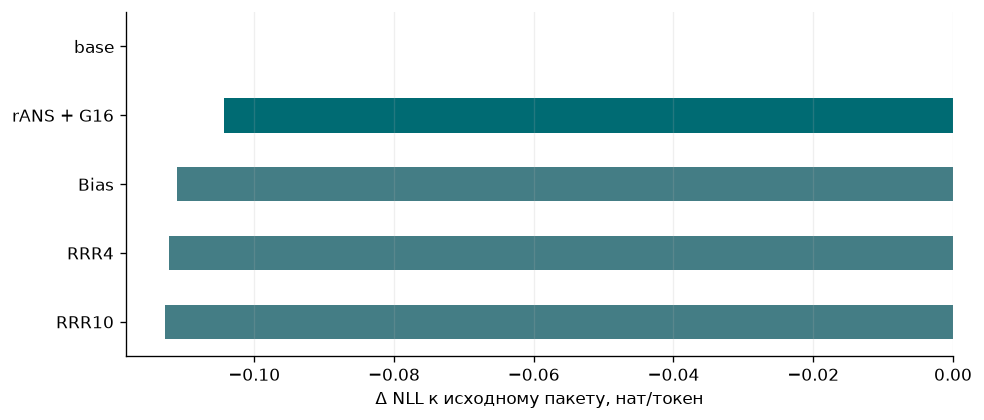

In [5]:
gate = pd.read_csv(results / "gate16.csv")
assert len(gate) == 17 and gate["full_bytes"].eq(73010643).all()
points = gate[gate["calibration"].isna()].set_index("method")["ppl"]
mlp = gate[gate["calibration"].notna()]
assert mlp.groupby("method").size().eq(3).all()
family_ppl = np.exp(np.log(mlp["ppl"]).groupby(mlp["method"]).mean()).loc[["Bias", "RRR4", "RRR10"]]
display(points.rename("PPL").to_frame().round(5))
display(family_ppl.rename("exp(mean NLL)").to_frame().round(5))

head = "known entropy+headG16"
plotted = pd.concat([points.loc[["base", head]].rename(index={head: "rANS + G16"}), family_ppl])
delta_nll = np.log(plotted / plotted.loc["base"])
ax = delta_nll.plot.barh(figsize=(8.3, 3.6), color=["#69788b", "#006b73", "#447d85", "#447d85", "#447d85"])
ax.set(xlabel="Δ NLL к исходному пакету, нат/токен", ylabel="")
ax.grid(axis="x", alpha=.2)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

Простая bias-поправка уже даёт большую часть эффекта от коррекции MLP. Интервалы для дополнительной пользы RRR относительно bias и для разницы RRR10–RRR4 включают ноль. Перенос небольших поправок на C4 и Tiny тоже неоднороден. Закрытый test и SEALED64 для выбора рецепта не открывались.

Итог серии — измеренный выигрыш перераспределения байтов в данном протоколе и набор отрицательных проверок собственных гипотез. PPL получена после восстановления весов в FP32. Байты описывают сериализованный пакет, задержку и VRAM INT4-инференса здесь не измерял.

Источник исторических E07/E08/E12 и QK — локальный `private/day10h_v1/READOUT.md`. Сводное парное сравнение 11 подходов — `private/continuation72h_v1/lab_report_v1/ИТОГ_ДЛЯ_КОЛЛЕГИ.md`. Сводка поздней серии — `private/continuation72h_v1/final_push20h_v1/FINAL_REPORT.md`.

## Таблицы и исходные записи

Слева — CSV, которые читает ноутбук. Справа — имена исходных локальных записей.

- [encoder_baselines.csv](results/encoder_baselines.csv) · `private/results/PPL.csv`
- [opt_followup.csv](results/opt_followup.csv) · `private/opt_window4h_repair/delivery/extracted/results/scientific_summary.json`
- [frozen_candidates.csv](results/frozen_candidates.csv) · `private/continuation72h_v1/report_completion_v2/FINAL_VERIFIED_PPL.json`, `private/continuation72h_v1/report_overlay_v2/FINAL_VERIFIED_PPL.json`, `private/continuation72h_v1/report_e03_v1/FINAL_VERIFIED_PPL.json`
- [gate16.csv](results/gate16.csv) · `private/continuation72h_v1/final_push20h_v1/gate_control01_v1/READOUT.md`, `private/continuation72h_v1/final_push20h_v1/known_mlp_eval01_v1/READOUT.md`